In [37]:
#!/usr/bin/env python3
# merchant_ranking_model.py
# ---------------------------------------------------------------
# Ranking system:
#  - Stratify by segment_code (1..5)
#  - PCA (on standardized features) to derive component weights
#  - Linear Regression on PCA components to predict target
#  - Normalize scores across all merchants and pick Top 100
#  - Prints Top-N PCA feature weights per segment to console
#  - Saves outputs into ../data/out/
# ---------------------------------------------------------------

import os
import sys
import math
import numpy as np
import pandas as pd
from typing import List, Dict, Tuple

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import VarianceThreshold

# --------------------------- CONFIG --------------------------- #
# Inputs: prefer cleaned active merchants; fall back to curated
PREFERRED_INPUT = "../data/out/merchant_cleaned_active6m.csv"
FALLBACK_INPUT  = "../data/curated/merchant_overall.csv"

# Identity / grouping columns
ABN_COL        = "merchant_abn"
NAME_COL       = "name"
SEG_COL        = "segment_code"

# Target KPI to rank by
TARGET_COL     = "sum_total_dollar_value"

# Columns NOT to use as features
EXCLUDE_COLS   = {
    ABN_COL, SEG_COL, NAME_COL, TARGET_COL,
    "r2", "std_slope", "trend_nrmse", "primary_category",
    "take_rate", "min_fraud_probability", "max_fraud_probability",
    "fraud_count", "cagr_overall", "segmentation", "avg_monthly_tx_count", "avg_monthly_total_dollar_value"
}
# Exclude columns by pattern (e.g., outlier flags)
EXCLUDE_PATTERNS = ("__outlier",)

# PCA config
PCA_VARIANCE_THRESHOLD = 0.90   # retain ≥ 90% variance
PCA_MAX_COMPONENTS     = 10     # cap components

# Printing config
TOP_FEATURES_PRINT = 10         # print top-N PCA features per segment

# Output
OUT_DIR = "../data/out"
os.makedirs(OUT_DIR, exist_ok=True)

# Reproducibility
RANDOM_STATE = 42


In [38]:
# --------------------------- UTILS --------------------------- #
def load_input_dataframe() -> pd.DataFrame:
    """Load preferred input if it exists, else fallback."""
    path = PREFERRED_INPUT if os.path.exists(PREFERRED_INPUT) else FALLBACK_INPUT
    if not os.path.exists(path):
        raise FileNotFoundError(f"Neither {PREFERRED_INPUT} nor {FALLBACK_INPUT} found.")
    df = pd.read_csv(path, low_memory=False)
    print(f"[LOAD] {df.shape} rows from {path}")
    return df


def select_feature_cols(df: pd.DataFrame) -> List[str]:
    """Select numeric feature columns, excluding IDs/segment/target/flags/date-ish columns."""
    numeric_cols = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c])]
    feats = []
    for c in numeric_cols:
        if c in EXCLUDE_COLS:
            continue
        if any(pat in c for pat in EXCLUDE_PATTERNS):
            continue
        feats.append(c)
    if not feats:
        raise ValueError("No numeric feature columns found after exclusions.")
    return feats


def make_design_matrix(
    df_seg: pd.DataFrame,
    feature_cols: List[str],
    remove_zero_var: bool = True
) -> Tuple[pd.DataFrame, List[str]]:
    """Return X (features only), after removing any 0-variance columns."""
    X = df_seg[feature_cols].copy()
    # Replace inf/-inf with NaN, then median-impute
    X = X.replace([np.inf, -np.inf], np.nan)
    X = X.apply(lambda s: s.fillna(s.median()), axis=0)

    if remove_zero_var:
        vt = VarianceThreshold(threshold=0.0)
        vt.fit(X)
        kept_mask = vt.get_support()
        kept_cols = [c for c, keep in zip(X.columns, kept_mask) if keep]
        X = X[kept_cols]
        feature_cols = kept_cols

    if X.shape[1] == 0:
        raise ValueError("All features dropped after variance filtering.")
    return X, feature_cols


def fit_pca_lr_for_segment(
    df_seg: pd.DataFrame,
    feature_cols: List[str],
    target_col: str = TARGET_COL
) -> Dict[str, object]:
    """
    Fit StandardScaler -> PCA -> LinearRegression on a single segment.
    Returns dict with artifacts, predictions, and PCA weights.
    """
    # Design matrix & target
    X_raw, feature_cols_final = make_design_matrix(df_seg, feature_cols)
    # Drop rows where target is NaN (align X and y by index)
    if target_col not in df_seg.columns:
        raise ValueError(f"Target column '{target_col}' missing in segment dataframe.")
    valid_mask = df_seg[target_col].notna()
    if not valid_mask.any():
        raise ValueError("No non-NaN target values for this segment.")
    X_raw = X_raw.loc[valid_mask].copy()
    y_raw = df_seg.loc[valid_mask, target_col].astype(float).values
    if X_raw.shape[0] < 2 or y_raw.size < 2:
        raise ValueError("Not enough rows with valid target after dropping NaNs.")
 

    # Stabilize with log1p (handles zeros)
    y = np.log1p(np.clip(y_raw, a_min=0, a_max=None))

    # Standardize
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_raw)

    # PCA (decide components via cumulative variance; cap at max)
    pca_full = PCA(random_state=RANDOM_STATE).fit(X_scaled)
    cumvar = np.cumsum(pca_full.explained_variance_ratio_)
    n_components = min(PCA_MAX_COMPONENTS, np.searchsorted(cumvar, PCA_VARIANCE_THRESHOLD) + 1)

    pca = PCA(n_components=n_components, random_state=RANDOM_STATE)
    X_pca = pca.fit_transform(X_scaled)

    # Linear regression on PCs
    reg = LinearRegression()
    reg.fit(X_pca, y)

    # Predictions (back-transform)
    y_pred_log = reg.predict(X_pca)
    y_pred = np.expm1(y_pred_log)

    # Assemble preds for only the rows used to fit/predict (avoid length mismatch)
    preds = df_seg.loc[valid_mask, [ABN_COL, NAME_COL, SEG_COL]].copy()
    preds["score_raw"] = y_pred.astype(float)

    # PCA feature weights (variance-weighted absolute loadings)
    comp_loadings = pca.components_                            # [n_components, n_features]
    comp_var_ratio = pca.explained_variance_ratio_.reshape(-1, 1)  # [n_components, 1]
    feature_weights = np.sum(np.abs(comp_loadings) * comp_var_ratio, axis=0)

    weights_df = pd.DataFrame({
        "feature": feature_cols_final,
        "pca_weight": feature_weights
    }).sort_values("pca_weight", ascending=False).reset_index(drop=True)

    # Also include explained variance metadata for transparency
    evr = pca.explained_variance_ratio_
    evr_cum = np.cumsum(evr)
    evr_df = pd.DataFrame({
        "component": np.arange(1, n_components + 1),
        "explained_variance_ratio": evr,
        "explained_variance_ratio_cum": evr_cum
    })

    return {
        "scaler": scaler,
        "pca": pca,
        "reg": reg,
        "feature_cols": feature_cols_final,
        "preds": preds,
        "weights": weights_df,
        "evr": evr_df,
        "n_components": n_components
    }


def normalize_scores(df_scores: pd.DataFrame, score_col: str = "score_raw", method: str = "standard", clip_std: float = 3.0) -> pd.DataFrame:
    """Min-max normalize score to 0..100 across all segments (global ranking)."""
    s = df_scores[score_col].astype(float)

    if method == "minmax":
        s_min, s_max = float(s.min()), float(s.max())
        if math.isclose(s_max, s_min):
            df_scores["score_norm_0_100"] = 50.0
        else:
            df_scores["score_norm_0_100"] = (s - s_min) / (s_max - s_min) * 100.0
        return df_scores

    if method == "robust":
        med = float(s.median())
        q1 = float(s.quantile(0.25))
        q3 = float(s.quantile(0.75))
        iqr = q3 - q1
        if math.isclose(iqr, 0.0):
            # fallback to minmax if no IQR
            return normalize_scores(df_scores, score_col=score_col, method="minmax")
        r = (s - med) / iqr
        r_clipped = np.clip(r, -clip_std, clip_std)
        # map [-clip_std, clip_std] -> [0,100]
        df_scores["score_norm_0_100"] = ((r_clipped + clip_std) / (2 * clip_std)) * 100.0
        return df_scores

    # default / "standard"
    mu = float(s.mean())
    sigma = float(s.std(ddof=0))
    if math.isclose(sigma, 0.0):
        df_scores["score_norm_0_100"] = 50.0
        return df_scores

    z = (s - mu) / sigma
    z_clipped = np.clip(z, -clip_std, clip_std)
    # map [-clip_std, clip_std] -> [0,100]
    df_scores["score_norm_0_100"] = ((z_clipped + clip_std) / (2 * clip_std)) * 100.0
    return df_scores


def rank_and_save(
    all_preds: pd.DataFrame,
    top_k: int = 100,
    out_dir: str = OUT_DIR
) -> tuple:
    """Create rankings, save CSVs, and return file paths."""
    # Global normalized ranking
    all_preds = normalize_scores(all_preds, "score_raw")
    all_preds = all_preds.sort_values("score_norm_0_100", ascending=False)
    all_preds["rank_overall"] = np.arange(1, len(all_preds) + 1)

    # Top K overall
    top_k_df = all_preds.head(top_k).copy()
    top_k_df["Top100_flag"] = True

    # Per-segment “top” (same K cap per segment for convenience)
    per_segment_top_path = os.path.join(out_dir, "rankings_per_segment_top.csv")
    per_segment_top = (
        all_preds
        .sort_values([SEG_COL, "score_norm_0_100"], ascending=[True, False])
        .groupby(SEG_COL)
        .head(min(100, all_preds[SEG_COL].value_counts().max()))
        .copy()
    )

    # Save
    all_path    = os.path.join(out_dir, "rankings_all_segments.csv")
    top100_path = os.path.join(out_dir, "rankings_top100_overall.csv")
    weights_path= os.path.join(out_dir, "pca_feature_weights_by_segment.csv")
    evr_path    = os.path.join(out_dir, "pca_explained_variance_by_segment.csv")

    all_preds.to_csv(all_path, index=False)
    top_k_df.to_csv(top100_path, index=False)
    per_segment_top.to_csv(per_segment_top_path, index=False)

    print(f"[SAVE] Full rankings         -> {all_path}")
    print(f"[SAVE] Top {top_k} overall    -> {top100_path}")
    print(f"[SAVE] Per-segment top (wide) -> {per_segment_top_path}")

    return all_path, top100_path, weights_path, evr_path

In [39]:
# --------------------------- MAIN FLOW --------------------------- #
def main():
    df = load_input_dataframe()

    # Sanity checks
    for col in [ABN_COL, SEG_COL, TARGET_COL]:
        if col not in df.columns:
            raise ValueError(f"Required column missing: {col}")

    # Ensure segment numeric
    if not pd.api.types.is_numeric_dtype(df[SEG_COL]):
        df[SEG_COL] = pd.to_numeric(df[SEG_COL], errors="coerce")

    # Feature selection
    feature_cols = select_feature_cols(df)
    print(f"[FEATS] Using {len(feature_cols)} feature columns.")

    # Containers
    all_preds = []
    all_weights = []
    all_evr = []

    segments = sorted([s for s in df[SEG_COL].dropna().unique().tolist() if str(s) != "nan"])
    print(f"[SEGMENTS] Found segments: {segments}")

    for seg in segments:
        df_seg = df[df[SEG_COL] == seg].copy()
        if df_seg.shape[0] < 20:
            print(f"[WARN] Segment {seg} has too few rows ({df_seg.shape[0]}). Skipping.")
            continue

        try:
            arts = fit_pca_lr_for_segment(df_seg, feature_cols, TARGET_COL)

            # Collect predictions
            seg_preds = arts["preds"].copy()
            seg_preds[SEG_COL] = seg
            all_preds.append(seg_preds)

            # Collect weights
            seg_w = arts["weights"].copy()
            seg_w[SEG_COL] = seg
            all_weights.append(seg_w)

            # Collect explained variance info
            seg_evr = arts["evr"].copy()
            seg_evr[SEG_COL] = seg
            all_evr.append(seg_evr)

            # ---- PRINT TOP PCA WEIGHTS (console) ----
            print(f"\n[PCA WEIGHTS] Segment {seg} — top {TOP_FEATURES_PRINT} features")
            print(seg_w.head(TOP_FEATURES_PRINT).to_string(index=False))

            # Also print EVR summary
            evr_cum_last = seg_evr["explained_variance_ratio_cum"].iloc[-1]
            print(f"[PCA EVR] Segment {seg}: components={arts['n_components']}, cumulative_variance={evr_cum_last:.3f}")

            print(f"[OK] Segment {seg}: n={df_seg.shape[0]}, comps={arts['n_components']}, feats={len(arts['feature_cols'])}")

        except Exception as e:
            print(f"[ERROR] Segment {seg}: {e}")

    if not all_preds:
        raise RuntimeError("No segments produced predictions. Check data and config.")

    all_preds_df = pd.concat(all_preds, ignore_index=True)

    # Normalize & rank
    all_path, top100_path, weights_path, evr_path = rank_and_save(all_preds_df, top_k=100, out_dir=OUT_DIR)

    # Save PCA weights & EVR by segment
    weights_df = pd.concat(all_weights, ignore_index=True) if all_weights else pd.DataFrame(columns=[SEG_COL,"feature","pca_weight"])
    weights_df = weights_df.sort_values([SEG_COL, "pca_weight"], ascending=[True, False])
    weights_df.to_csv(weights_path, index=False)
    print(f"[SAVE] PCA feature weights by segment -> {weights_path}")

    evr_df = pd.concat(all_evr, ignore_index=True) if all_evr else pd.DataFrame(columns=["component","explained_variance_ratio","explained_variance_ratio_cum",SEG_COL])
    evr_df = evr_df.sort_values([SEG_COL, "component"])
    evr_df.to_csv(evr_path, index=False)
    print(f"[SAVE] PCA explained variance by segment -> {evr_path}")

    print("\nDone.")
    

In [40]:
if __name__ == "__main__":
    try:
        main()
    except Exception as e:
        print(f"[FATAL] {e}")
        sys.exit(1)

[LOAD] (4026, 31) rows from ../data/curated/merchant_overall.csv
[FEATS] Using 12 feature columns.
[SEGMENTS] Found segments: [1, 2, 3, 4, 5]

[PCA WEIGHTS] Segment 1 — top 10 features
                     feature  pca_weight  segment_code
               active_months    0.220677             1
        overall_avg_tx_value    0.209349             1
             tx_per_customer    0.206006             1
                sum_tx_count    0.204359             1
avg_monthly_unique_customers    0.201267             1
 median_tot_prsnl_inc_weekly    0.200799             1
 total_yr12_completion_ratio    0.186746             1
        total_tertiary_ratio    0.185251             1
             pos_month_share    0.172529             1
    unique_users_all_periods    0.164929             1
[PCA EVR] Segment 1: components=6, cumulative_variance=0.909
[OK] Segment 1: n=976, comps=6, feats=11

[PCA WEIGHTS] Segment 2 — top 10 features
                     feature  pca_weight  segment_code
        ov

/Users/yuanern/Documents/unimelb/Applied Data Science/Assignment 2/venv/lib/python3.10/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/yuanern/Documents/unimelb/Applied Data Science/Assignment 2/venv/lib/python3.10/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/Users/yuanern/Documents/unimelb/Applied Data Science/Assignment 2/venv/lib/python3.10/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: invalid value encountered in matmul
  X_transformed = X @ self.components_.T
/Users/yuanern/Documents/unimelb/Applied Data Science/Assignment 2/venv/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/yuanern/Documents/unimelb/Applied Data Science/Assignment 2/venv/lib/python3.10/s

In [41]:
#!/usr/bin/env python3
# merchant_ranking_viz.py
# ---------------------------------------------------------------
# Presentation visuals in green theme using bu_name instead of ABN
# ---------------------------------------------------------------

import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [42]:
# --------------------------- CONFIG --------------------------- #
OUT_DIR = "../data/out"
VIZ_DIR = os.path.join(OUT_DIR, "viz")
os.makedirs(VIZ_DIR, exist_ok=True)

RANKINGS_ALL = os.path.join(OUT_DIR, "rankings_all_segments.csv")
TOP100_PATH  = os.path.join(OUT_DIR, "rankings_top100_overall.csv")
WEIGHTS_PATH = os.path.join(OUT_DIR, "pca_feature_weights_by_segment.csv")

PREFERRED_INPUT = os.path.join(OUT_DIR, "merchant_cleaned_active6m.csv")
FALLBACK_INPUT  = "../data/curated/merchant_overall.csv"

SEG_COL    = "segment_code"
TARGET_COL = "sum_total_dollar_value"

# Name column preferences
CANDIDATE_NAME_COLS = ["bu_name", "merchant_name", "merchant_display_name", "legal_name", "trading_name", "name"]
FALLBACK_ID_COL     = "merchant_abn"

# Visualization settings
TOPN_OVERALL  = 20
TOPN_PER_SEG  = 20
TOPN_FEATURES = 10

# Green palette 🌿
GREEN_LIGHT  = "#a1d99b"
GREEN_MEDIUM = "#74c476"
GREEN_DARK   = "#31a354"
GREEN_DEEP   = "#006d2c"
GREEN_DEEPEST= "#00441b"
GREEN_LIST   = [GREEN_LIGHT, GREEN_MEDIUM, GREEN_DARK, GREEN_DEEP, GREEN_DEEPEST]

plt.rcParams.update({
    "axes.facecolor": "white",
    "axes.edgecolor": "black",
    "axes.labelcolor": "black",
    "text.color": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "font.size": 11
})

In [43]:
# --------------------------- HELPERS --------------------------- #
def require(path: str):
    if not os.path.exists(path):
        raise FileNotFoundError(f"Missing expected input: {path}")
    return path

def load_base():
    if os.path.exists(PREFERRED_INPUT):
        return pd.read_csv(PREFERRED_INPUT, low_memory=False)
    return pd.read_csv(require(FALLBACK_INPUT), low_memory=False)

def choose_name_col(df: pd.DataFrame) -> str:
    for c in CANDIDATE_NAME_COLS:
        if c in df.columns:
            return c
    return FALLBACK_ID_COL

def fig_save(path: str):
    plt.tight_layout()
    plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()


In [44]:
# --------------------------- CHARTS --------------------------- #
def plot_segment_share_in_top100(top100: pd.DataFrame):
    counts = top100[SEG_COL].value_counts().sort_index()
    plt.figure()
    plt.bar(counts.index.astype(str), counts.values, color=GREEN_DARK)
    plt.title("Segment Share in Top 100")
    plt.xlabel("Segment")
    plt.ylabel("Count in Top 100")
    fig_save(os.path.join(VIZ_DIR, "top100_segment_share.png"))

def plot_top20_overall(all_rankings: pd.DataFrame, name_col: str):
    top20 = all_rankings.nlargest(TOPN_OVERALL, "score_norm_0_100")[
        [name_col, SEG_COL, "score_norm_0_100"]
    ].copy()
    top20 = top20.iloc[::-1]
    plt.figure(figsize=(9, 10))
    colors = [GREEN_LIST[i % len(GREEN_LIST)] for i in range(len(top20))]
    plt.barh(top20[name_col].astype(str), top20["score_norm_0_100"].values, color=colors)
    plt.title("Top 20 Merchants Overall (Normalized Score)")
    plt.xlabel("Normalized Score (0–100)")
    plt.ylabel("Merchant")
    for i, (_, row) in enumerate(top20.iterrows()):
        plt.text(row["score_norm_0_100"] + 1, i, f"Seg {int(row[SEG_COL])}", va="center", color=GREEN_DEEP)
    fig_save(os.path.join(VIZ_DIR, "top20_overall_barh.png"))

def plot_topN_per_segment(all_rankings: pd.DataFrame, name_col: str):
    segments = sorted(all_rankings[SEG_COL].dropna().unique())
    for seg in segments:
        sub = all_rankings[all_rankings[SEG_COL] == seg].nlargest(
            TOPN_PER_SEG, "score_norm_0_100"
        )[[name_col, "score_norm_0_100"]].copy()
        sub = sub.iloc[::-1]
        plt.figure(figsize=(9, 10))
        colors = [GREEN_LIST[i % len(GREEN_LIST)] for i in range(len(sub))]
        plt.barh(sub[name_col].astype(str), sub["score_norm_0_100"].values, color=colors)
        plt.title(f"Top {TOPN_PER_SEG} Merchants – Segment {int(seg)}")
        plt.xlabel("Normalized Score (0–100)")
        plt.ylabel("Merchant")
        fig_save(os.path.join(VIZ_DIR, f"top{TOPN_PER_SEG}_segment_{int(seg)}.png"))

def plot_score_distribution_by_segment(all_rankings: pd.DataFrame):
    plt.figure()
    order = sorted(all_rankings[SEG_COL].dropna().unique())
    data = [all_rankings.loc[all_rankings[SEG_COL] == seg, "score_norm_0_100"].dropna() for seg in order]
    box = plt.boxplot(data, labels=[str(int(seg)) for seg in order], patch_artist=True)
    for patch in box["boxes"]:
        patch.set_facecolor(GREEN_MEDIUM)
    plt.title("Score Distribution by Segment (Normalized 0–100)")
    plt.xlabel("Segment")
    plt.ylabel("Normalized Score")
    fig_save(os.path.join(VIZ_DIR, "score_distribution_by_segment.png"))

def plot_pca_cumulative_variance(weights_df: pd.DataFrame):
    for seg in sorted(weights_df["segment_code"].dropna().unique()):
        w = weights_df[weights_df["segment_code"] == seg].copy()
        if w.empty:
            continue
        w = w.sort_values("pca_weight", ascending=False)
        w["cum_share"] = w["pca_weight"].cumsum() / w["pca_weight"].sum()
        plt.figure()
        plt.plot(range(1, len(w) + 1), w["cum_share"].values, marker="o", color=GREEN_DARK)
        plt.title(f"PCA Feature Weight Concentration – Segment {int(seg)}")
        plt.xlabel("Top-k Features")
        plt.ylabel("Cumulative Share of Weight")
        fig_save(os.path.join(VIZ_DIR, f"pca_weight_cum_segment_{int(seg)}.png"))

def plot_pca_feature_weights_topN(weights_df: pd.DataFrame):
    for seg in sorted(weights_df["segment_code"].dropna().unique()):
        w = weights_df[weights_df["segment_code"] == seg].copy()
        if w.empty:
            continue
        w = w.sort_values("pca_weight", ascending=False).head(TOPN_FEATURES)
        w = w.iloc[::-1]
        colors = [GREEN_LIST[i % len(GREEN_LIST)] for i in range(len(w))]
        plt.figure(figsize=(9, 6))
        plt.barh(w["feature"].astype(str), w["pca_weight"].values, color=colors)
        plt.title(f"Top {TOPN_FEATURES} PCA-Weighted Features – Segment {int(seg)}")
        plt.xlabel("PCA Weight")
        plt.ylabel("Feature")
        fig_save(os.path.join(VIZ_DIR, f"pca_weights_top{TOPN_FEATURES}_segment_{int(seg)}.png"))

def plot_pred_vs_actual_by_segment(all_rankings: pd.DataFrame, base_df: pd.DataFrame, name_col: str):
    if name_col not in all_rankings.columns or name_col not in base_df.columns:
        print(f"[WARN] Skipping calibration: '{name_col}' not in both.")
        return
    j = all_rankings[[name_col, SEG_COL, "score_raw"]].merge(
        base_df[[name_col, SEG_COL, TARGET_COL]],
        on=[name_col, SEG_COL], how="inner"
    ).dropna(subset=["score_raw", TARGET_COL])

    if j.empty:
        return

    j["log_pred"]   = np.log1p(j["score_raw"].astype(float))
    j["log_actual"] = np.log1p(j[TARGET_COL].astype(float))

    for seg in sorted(j[SEG_COL].dropna().unique()):
        sub = j[j[SEG_COL] == seg].copy()
        plt.figure()
        plt.scatter(sub["log_actual"].values, sub["log_pred"].values, s=10, alpha=0.6, color=GREEN_DARK)
        m = min(sub[["log_actual","log_pred"]].min().min(),)
        M = max(sub[["log_actual","log_pred"]].max().max(),)
        plt.plot([m, M], [m, M], linestyle="--", color=GREEN_DEEP)
        plt.title(f"Predicted vs Actual (log scale) – Segment {int(seg)}")
        plt.xlabel(f"log(1+{TARGET_COL})")
        plt.ylabel("log(1+Predicted)")
        fig_save(os.path.join(VIZ_DIR, f"calibration_segment_{int(seg)}.png"))


[INFO] Using name column: name


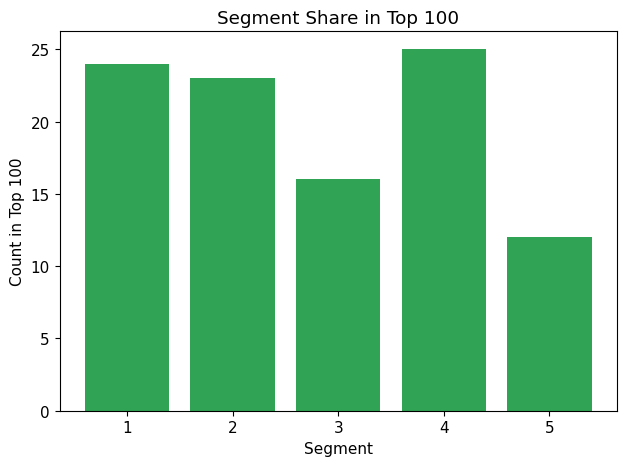

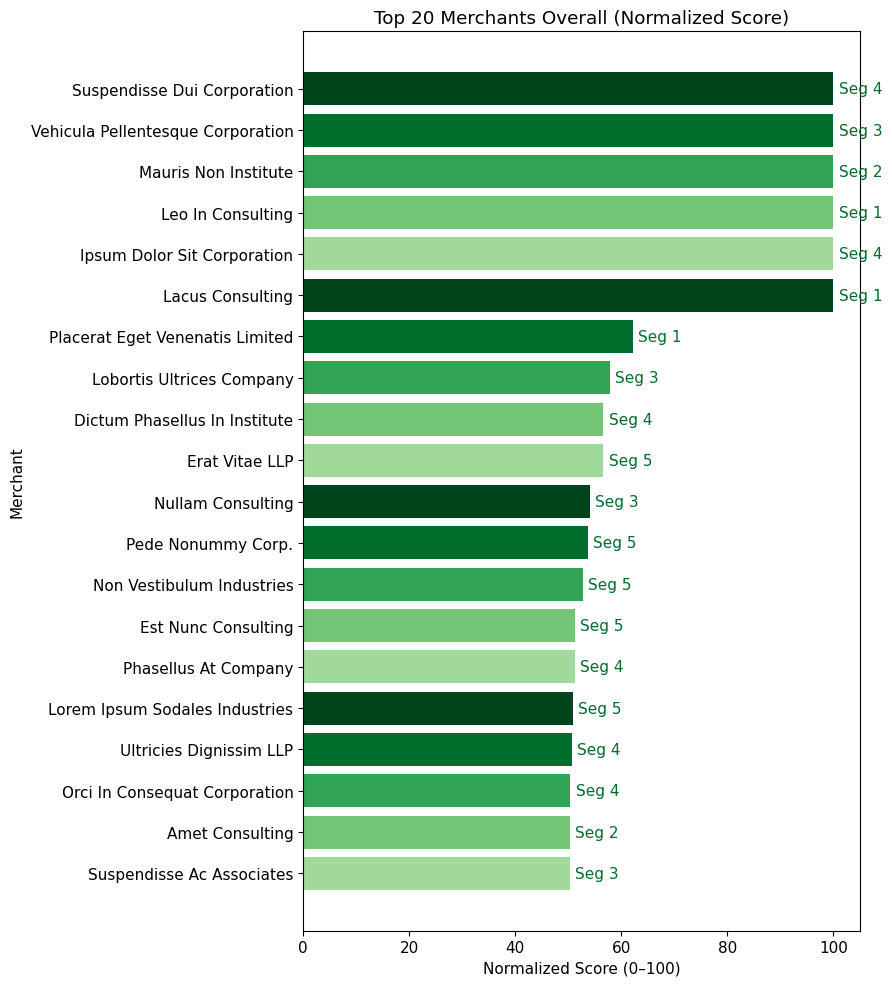

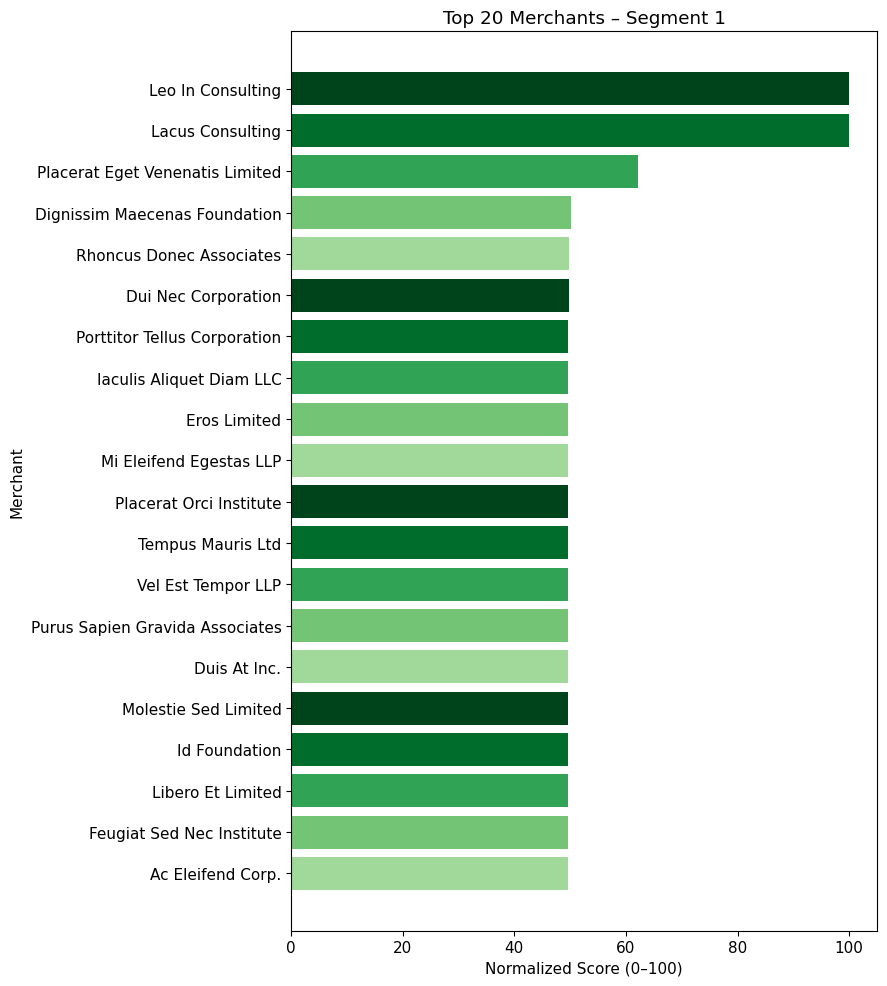

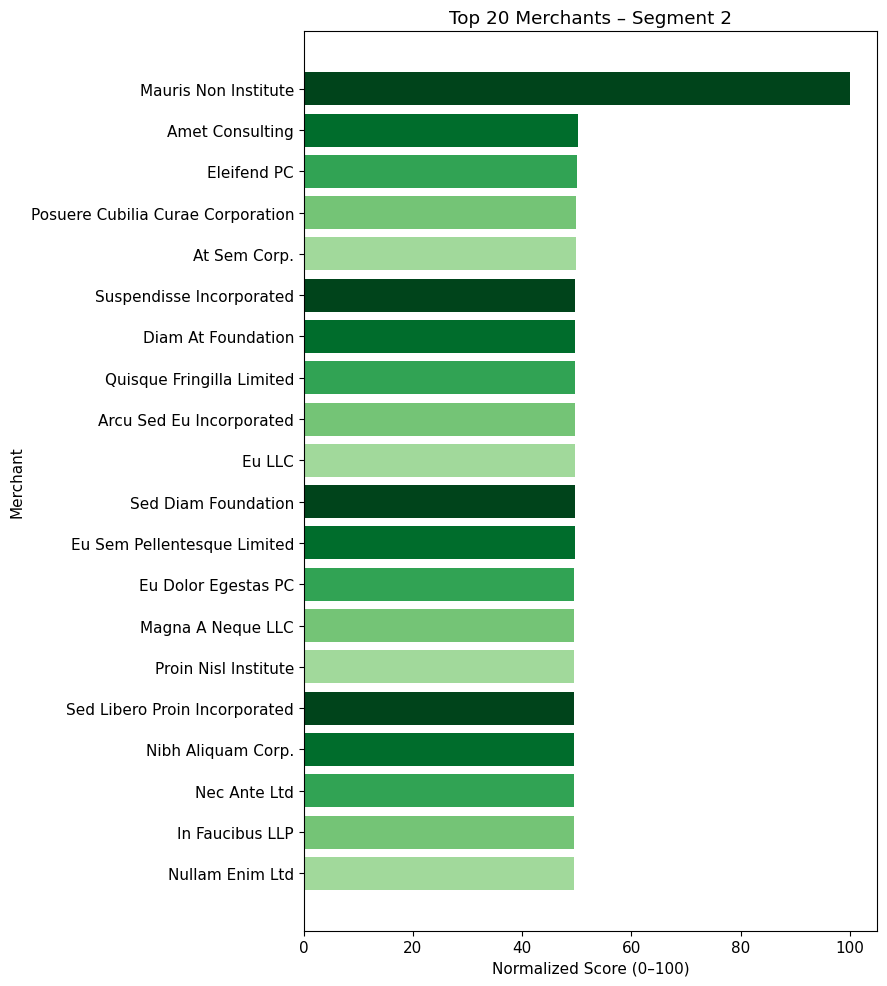

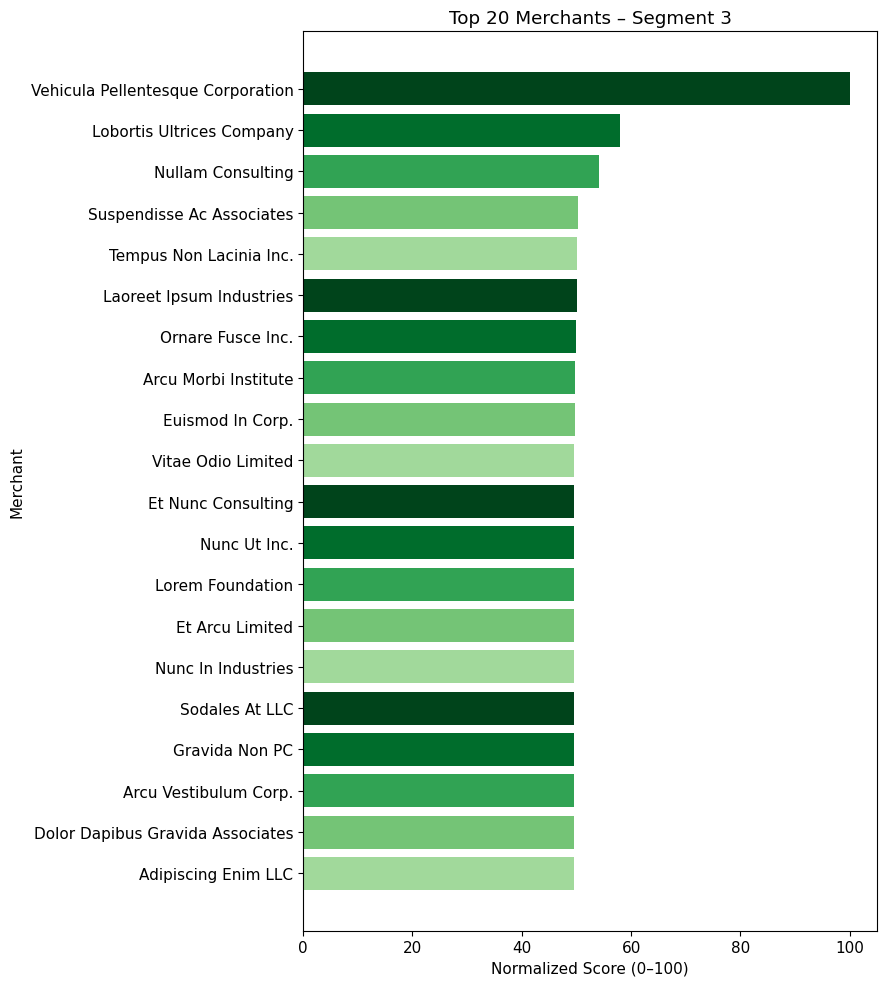

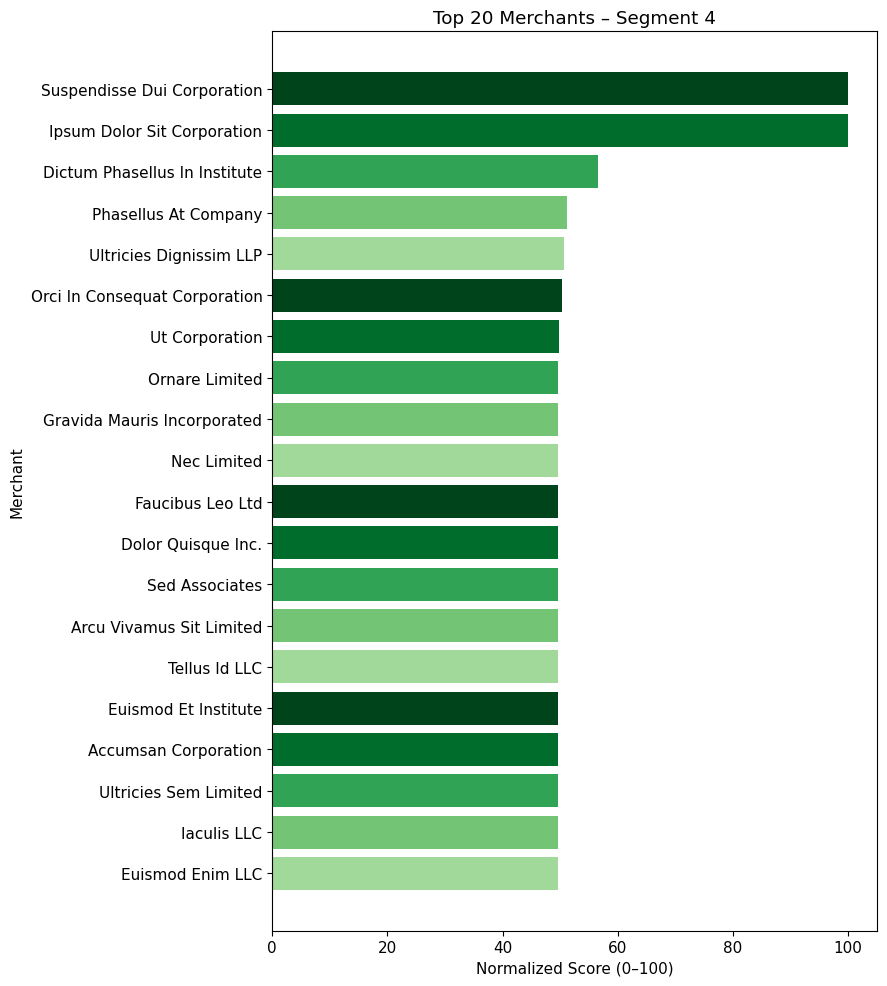

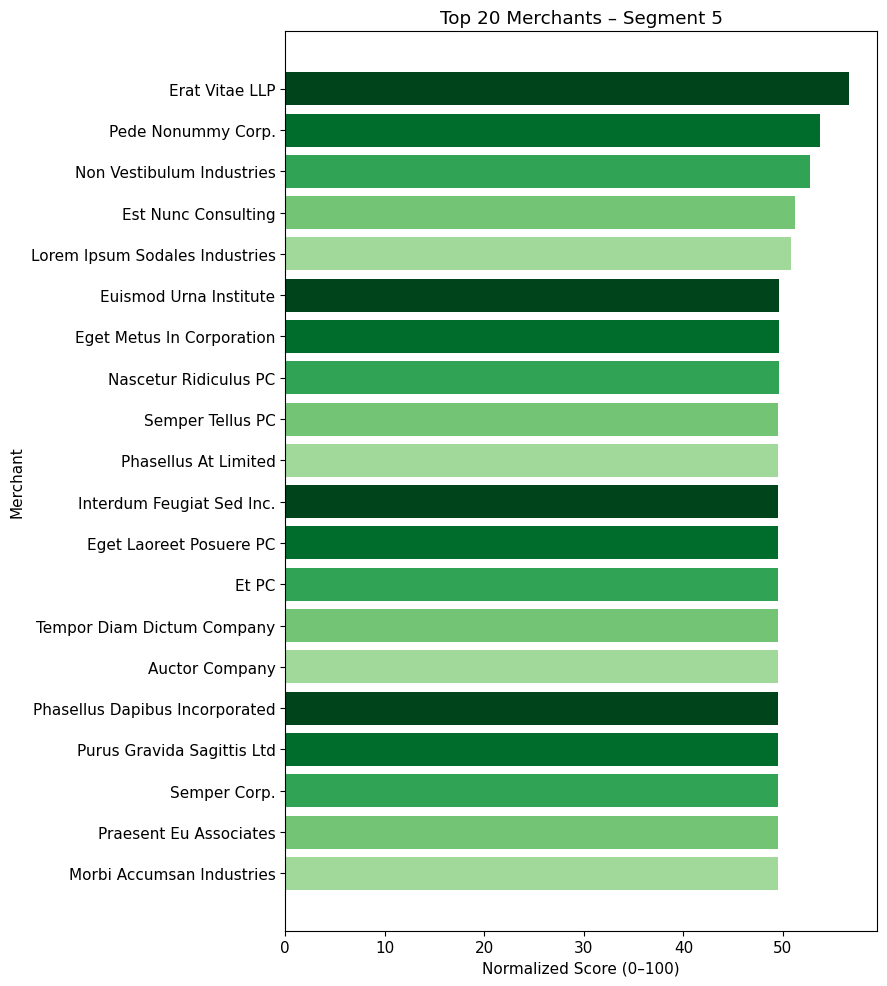

/var/folders/g0/cyd5fgtd29d93g_sc2mxqw4m0000gn/T/ipykernel_38291/3003422053.py:45: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = plt.boxplot(data, labels=[str(int(seg)) for seg in order], patch_artist=True)


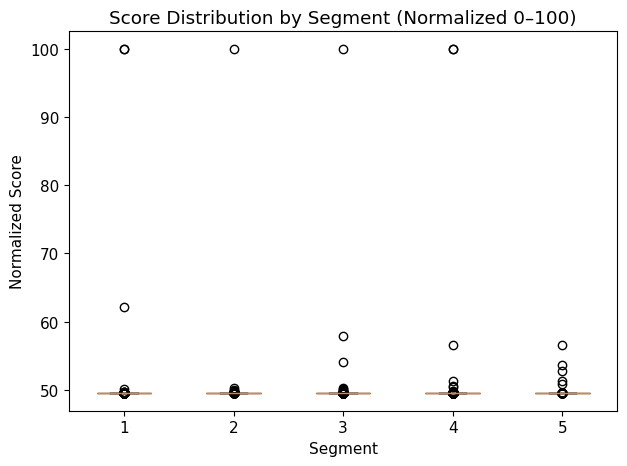

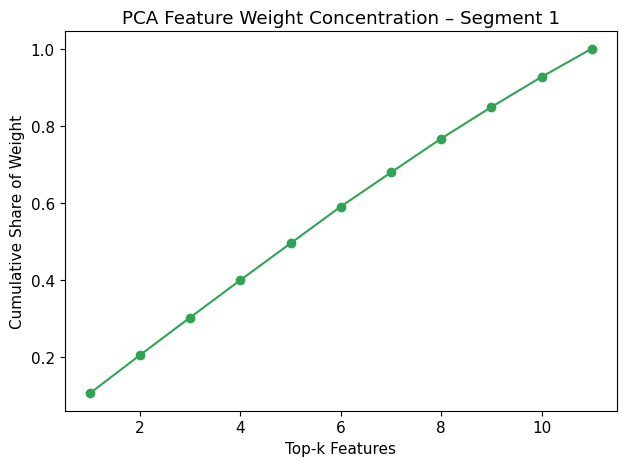

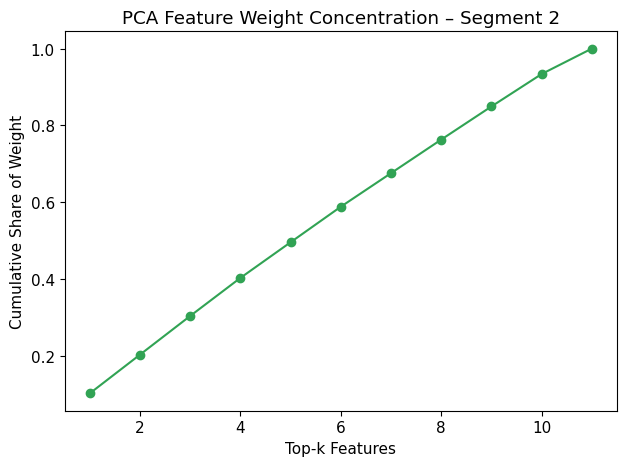

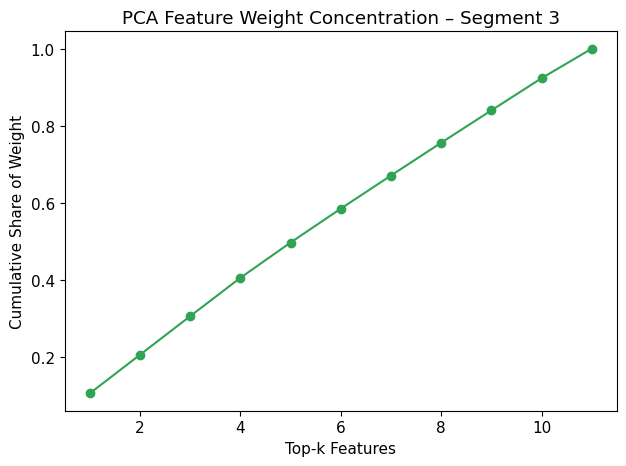

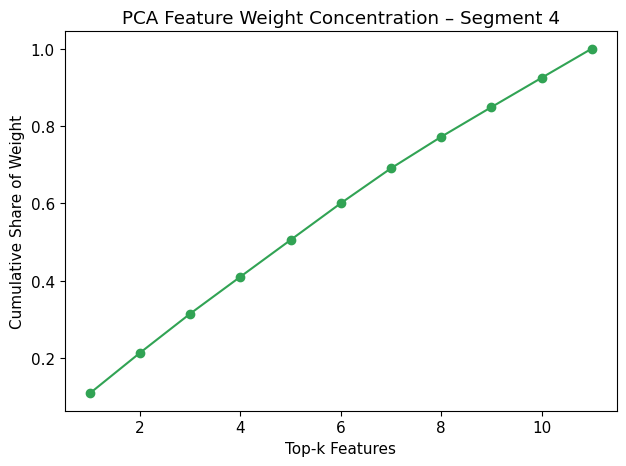

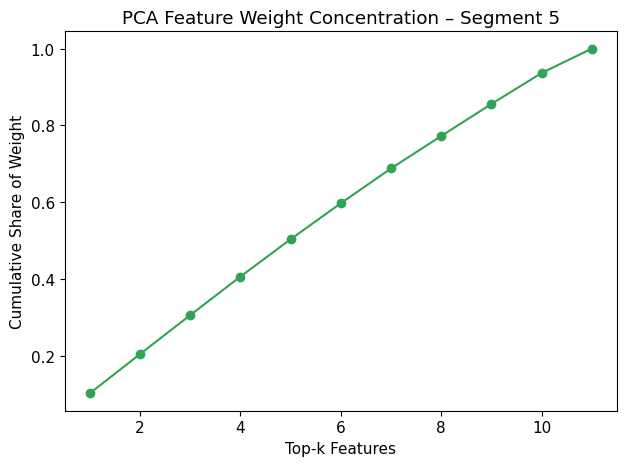

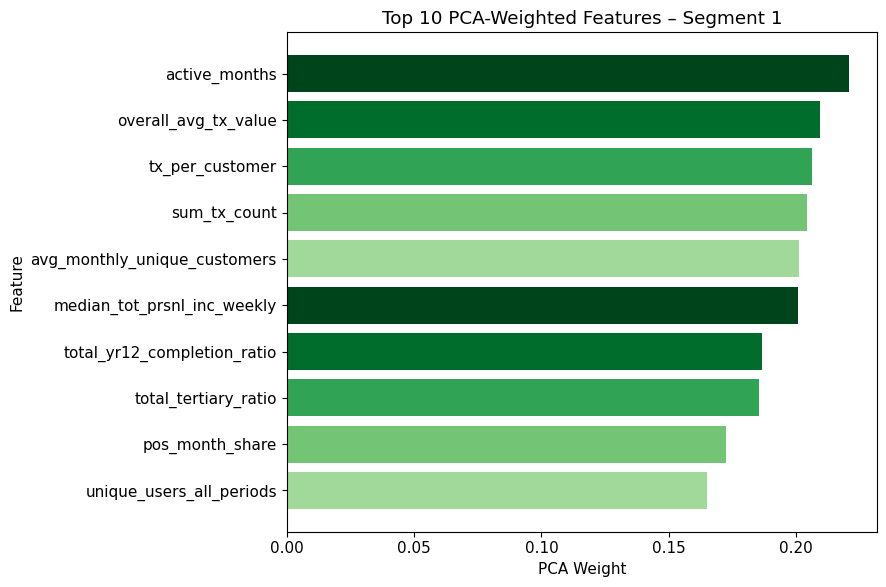

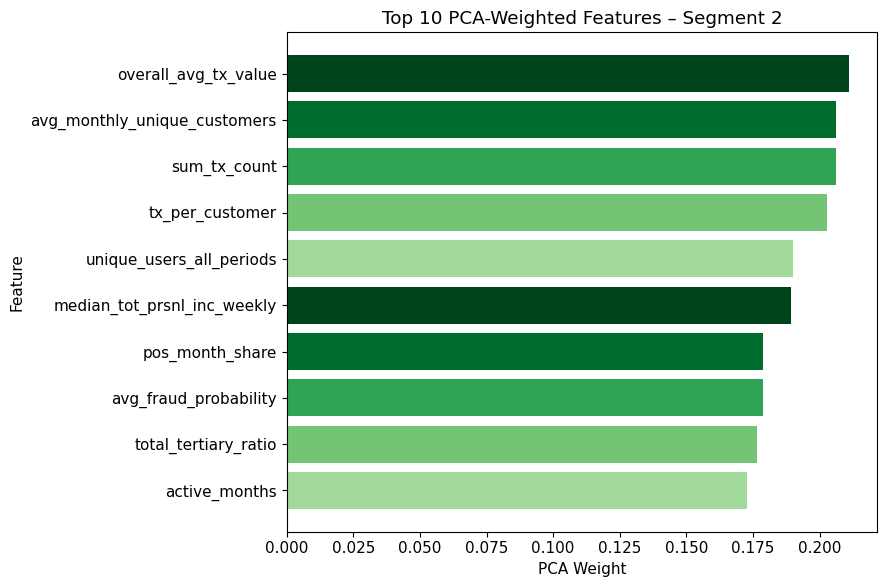

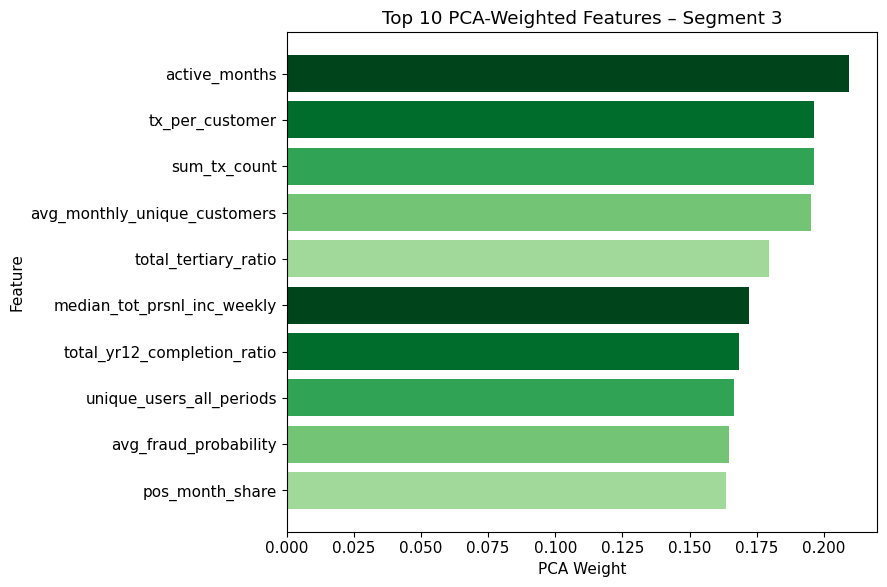

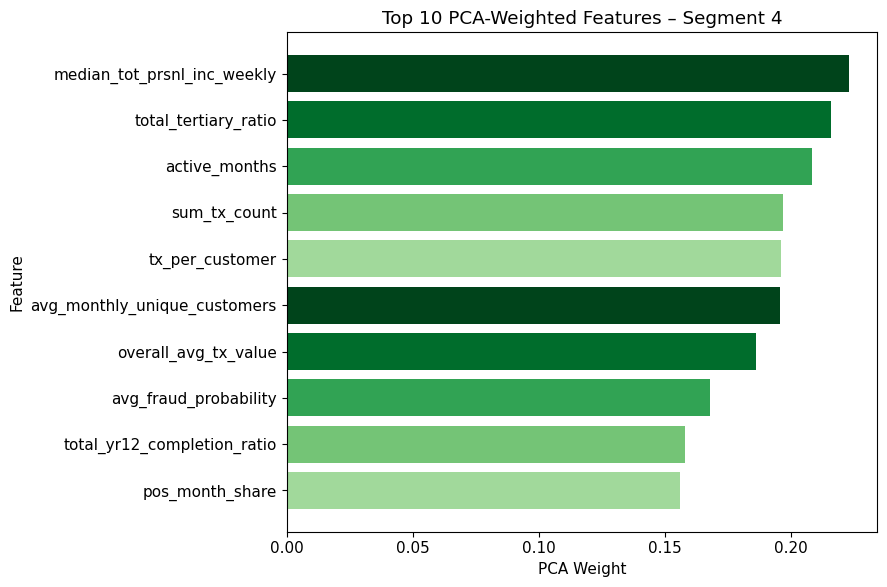

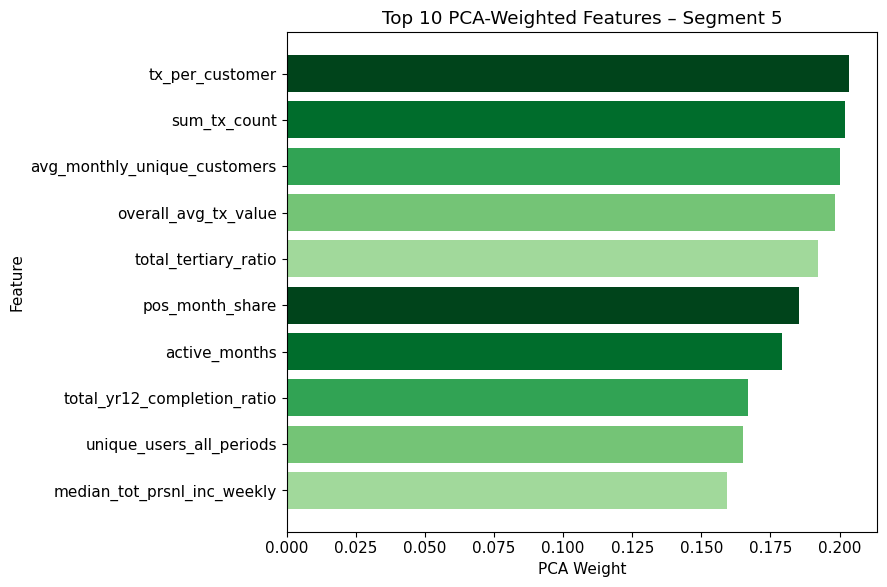

[WARN] Skipping calibration charts: 'numpy.float64' object is not iterable

[OK] Green visuals saved to: ../data/out/viz


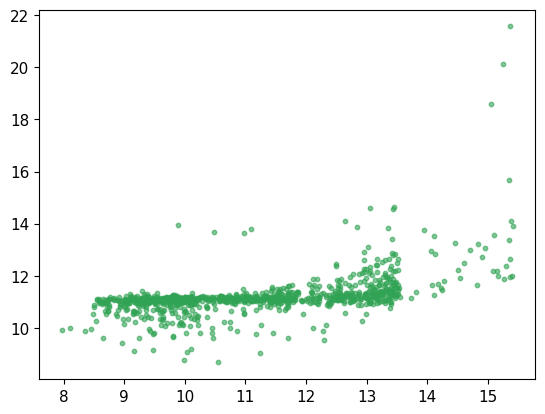

In [45]:
# --------------------------- MAIN --------------------------- #
def main():
    rankings_all = pd.read_csv(require(RANKINGS_ALL), low_memory=False)
    top100       = pd.read_csv(require(TOP100_PATH), low_memory=False)
    weights      = pd.read_csv(require(WEIGHTS_PATH), low_memory=False)

    name_col = choose_name_col(rankings_all)
    print(f"[INFO] Using name column: {name_col}")

    if not pd.api.types.is_numeric_dtype(rankings_all[SEG_COL]):
        rankings_all[SEG_COL] = pd.to_numeric(rankings_all[SEG_COL], errors="coerce")
    if not pd.api.types.is_numeric_dtype(top100[SEG_COL]):
        top100[SEG_COL] = pd.to_numeric(top100[SEG_COL], errors="coerce")
    if not weights.empty and not pd.api.types.is_numeric_dtype(weights["segment_code"]):
        weights["segment_code"] = pd.to_numeric(weights["segment_code"], errors="coerce")

    plot_segment_share_in_top100(top100)
    plot_top20_overall(rankings_all, name_col)
    plot_topN_per_segment(rankings_all, name_col)
    plot_score_distribution_by_segment(rankings_all)

    if not weights.empty:
        plot_pca_cumulative_variance(weights)
        plot_pca_feature_weights_topN(weights)

    try:
        base = load_base()
        if not pd.api.types.is_numeric_dtype(base[SEG_COL]):
            base[SEG_COL] = pd.to_numeric(base[SEG_COL], errors="coerce")
        plot_pred_vs_actual_by_segment(rankings_all, base, name_col)
    except Exception as e:
        print(f"[WARN] Skipping calibration charts: {e}")

    print(f"\n[OK] Green visuals saved to: {VIZ_DIR}")

if __name__ == "__main__":
    main()
